# DIGITAL SIGNAL PROCESSING LABORATORY
## WEEK 2 — LAB 1A: SAMPLING, ALIASING AND QUANTIZATION

**Name:** Rahel B Faustin

**Registration No:** 240242411692  
**Class:** BENG24COE - 4

**Date:** 26th November 2026


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile
from IPython.display import Audio, display
import os

print("DSP Week 2 environment is ready.")

DSP Week 2 environment is ready.


## Task 2.1: Aliasing of a Sinusoid

### Objective
To demonstrate aliasing by sampling a 7 Hz sinusoidal signal at different sampling frequencies and observing how the apparent frequency changes.

### Theory
Aliasing occurs when a continuous-time signal is sampled at a frequency that is insufficient to represent its original frequency correctly.

According to the Nyquist sampling theorem, the sampling frequency must be at least twice the highest frequency component of the signal.

$$f_s \geq 2f_0$$

Where:

- $f_s$ = Sampling frequency.
- $f_0$ = Original signal frequency.
- $f_N = f_s/2$ = Nyquist frequency.

The alias frequency can be calculated using:

$$f_{alias}=|f_0-kf_s|$$

For this experiment, the original signal frequency is 7 Hz. When the sampling frequency is 10 Hz, the Nyquist frequency is:

$$f_N=\frac{10}{2}=5\text{ Hz}$$

Since the original frequency (7 Hz) is greater than the Nyquist frequency (5 Hz), aliasing occurs.

The apparent frequency becomes:

$$f_{alias}=|7-10|=3\text{ Hz}$$

### Expected Results

The following table shows the expected alias frequencies for the different sampling frequencies.

| Sampling Frequency ($f_s$) | Nyquist Frequency ($f_N$) | Expected Alias Frequency |
|---|---|---|
| 10 Hz | 5 Hz | 3 Hz |
| 12 Hz | 6 Hz | 5 Hz |
| 14 Hz | 7 Hz | 7 Hz |
| 20 Hz | 10 Hz | 7 Hz |

### Observation
The apparent frequency of the sampled signal depends on the sampling frequency. When the sampling frequency is too low, aliasing occurs and the signal appears to have a different frequency from its original frequency.

When the sampling frequency is 14 Hz or 20 Hz, the original 7 Hz signal satisfies the Nyquist criterion and can be represented without aliasing.

### Conclusion
The experiment demonstrates that sampling frequency plays an important role in digital signal processing. Sampling below the Nyquist rate causes aliasing, resulting in incorrect frequency representation. Therefore, an appropriate sampling frequency must be selected to avoid aliasing.

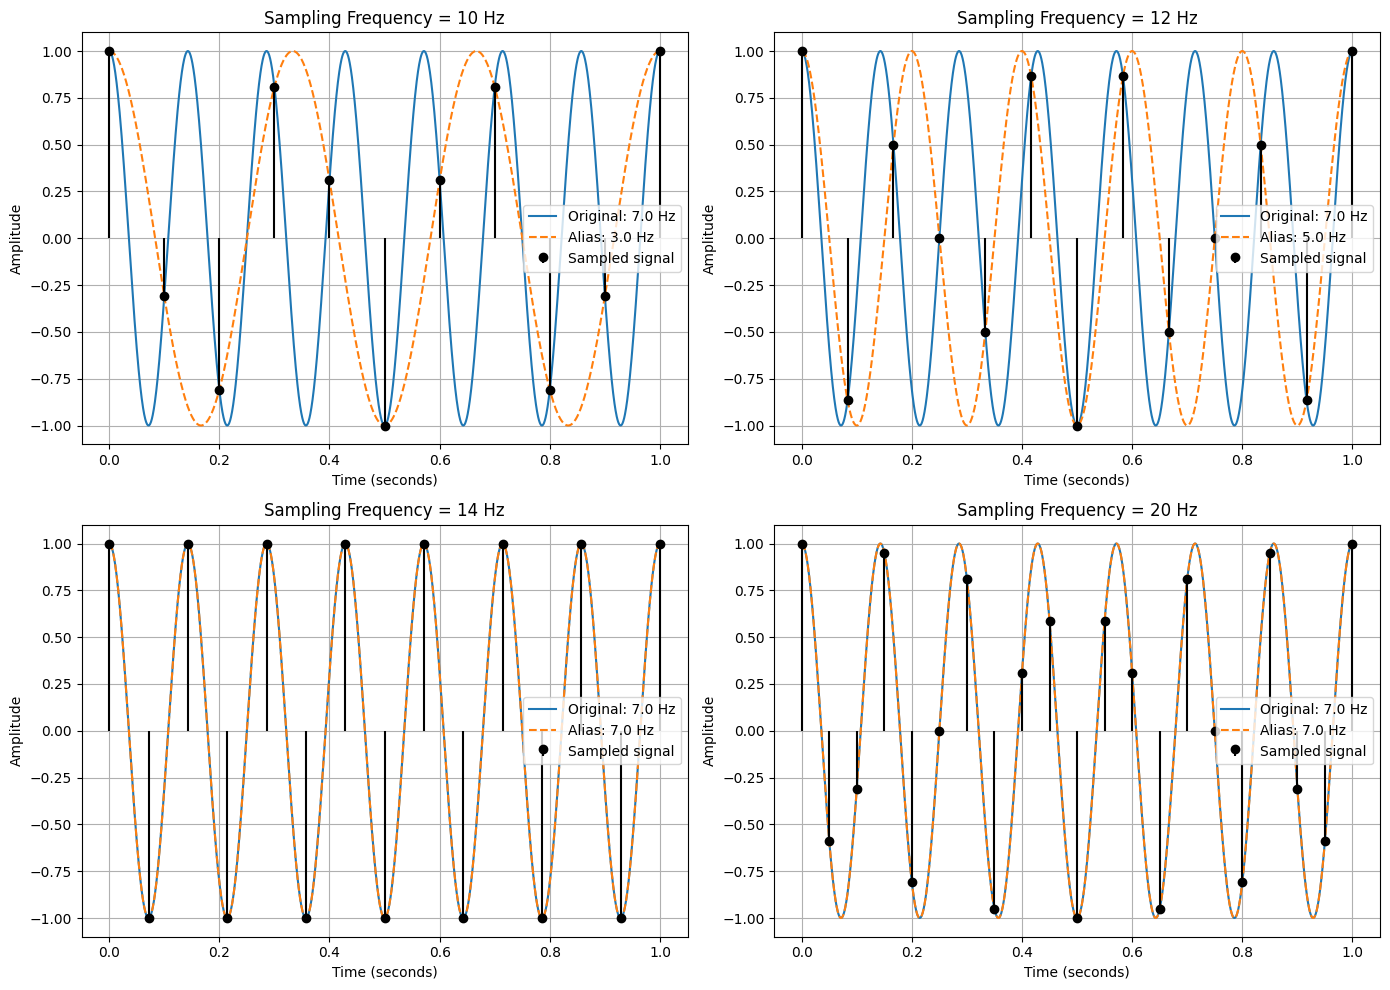

In [3]:
# Task 2.1: Aliasing of a Sinusoid

# Original signal frequency
f0 = 7.0

# Sampling frequencies to investigate
sampling_frequencies = [10, 12, 14, 20]

# Dense time vector representing the continuous signal
t = np.linspace(0, 1, 2000)

# Create a figure
plt.figure(figsize=(14, 10))

# Store alias frequencies
alias_results = []

for i, fs in enumerate(sampling_frequencies):

    # Calculate alias frequency
    f_alias = abs(f0 - fs * round(f0 / fs))

    # Discrete sampling points
    n = np.arange(0, int(fs) + 1)
    tn = n / fs

    # Original continuous signal
    x = np.cos(2 * np.pi * f0 * t)

    # Alias signal
    x_alias = np.cos(2 * np.pi * f_alias * t)

    # Sampled signal
    x_samples = np.cos(2 * np.pi * f0 * tn)

    # Plot
    plt.subplot(2, 2, i + 1)

    plt.plot(t, x, label=f"Original: {f0} Hz")
    plt.plot(t, x_alias, '--', label=f"Alias: {f_alias} Hz")

    plt.stem(
        tn,
        x_samples,
        linefmt='k-',
        markerfmt='ko',
        basefmt=' ',
        label='Sampled signal'
    )

    plt.title(f"Sampling Frequency = {fs} Hz")
    plt.xlabel("Time (seconds)")
    plt.ylabel("Amplitude")
    plt.legend()
    plt.grid(True)

    alias_results.append((fs, f_alias))

plt.tight_layout()
plt.show()

## Task 2.2: Hear Aliasing

### Objective
To demonstrate the effects of aliasing on an audio signal by reducing its sampling frequency and comparing the sound quality of two methods: naïve downsampling and downsampling with an anti-aliasing filter.

### Theory
Downsampling is the process of reducing the sampling rate of a digital signal by keeping fewer samples.

In this experiment, the original audio signal will be downsampled using factors of 2, 4 and 8.

**1. Naïve Downsampling**

Naïve downsampling is performed by keeping every $k$-th sample without applying a low-pass filter.

$$x_{\text{naive}}[n]=x[kn]$$

This method can introduce aliasing because high-frequency components may become incorrectly represented at the lower sampling frequency.

**2. Downsampling with an Anti-Aliasing Filter**

This method first applies a low-pass filter to remove frequency components that are too high for the new sampling rate. It then reduces the number of samples.

The anti-aliasing filter helps prevent unwanted frequency components from folding into the lower frequency range.

### Procedure
The Week 1 voice recording is used as the input audio signal. The signal is downsampled using factors of 2, 4 and 8. The resulting audio signals are played back and compared using headphones.

In [4]:
# Task 2.2: Load and Prepare Audio

fname = "voice.wav"

if os.path.exists(fname):
    fs, x = wavfile.read(fname)

    # Convert stereo audio to mono if necessary
    if x.ndim > 1:
        x = x.mean(axis=1)

    x = x.astype(float)

    # Normalize the audio signal
    peak = np.max(np.abs(x))
    if peak > 0:
        x = x / peak

    print("Audio loaded successfully.")
    print("Original sampling frequency:", fs, "Hz")
    print("Number of samples:", len(x))
    print("Duration:", len(x) / fs, "seconds")

else:
    print("Audio file not found. Please upload my_voice.wav.")

Audio loaded successfully.
Original sampling frequency: 48000 Hz
Number of samples: 272384
Duration: 5.674666666666667 seconds


In [5]:
# Downsampling using factors 2, 4 and 8

for k in [2, 4, 8]:

    # Naive downsampling without filtering
    naive = x[::k]

    # Proper downsampling with an anti-aliasing FIR filter
    proper = signal.decimate(x, k, ftype="fir")

    new_fs = fs // k

    print("\nDownsampling factor:", k)
    print("New sampling frequency:", new_fs, "Hz")

    print("Naive downsampling:")
    display(Audio(naive, rate=new_fs))

    print("Downsampling with anti-aliasing filter:")
    display(Audio(proper, rate=new_fs))


Downsampling factor: 2
New sampling frequency: 24000 Hz
Naive downsampling:


Downsampling with anti-aliasing filter:



Downsampling factor: 4
New sampling frequency: 12000 Hz
Naive downsampling:


Downsampling with anti-aliasing filter:



Downsampling factor: 8
New sampling frequency: 6000 Hz
Naive downsampling:


Downsampling with anti-aliasing filter:


### Observation
The audio signal was downsampled using factors of 2, 4 and 8. Two methods were compared: naïve downsampling without filtering and downsampling with an anti-aliasing filter.

The audio quality was evaluated by listening to the resulting signals using headphones.


### For k = 8

At a downsampling factor of 8, the original audio signal is reduced to one-eighth of its original number of samples.

The naïvely downsampled audio may experience aliasing because no anti-aliasing filter is applied before reducing the sampling rate. This can introduce distortion and make the voice sound unclear or unnatural.

In contrast, downsampling with an anti-aliasing FIR filter reduces high-frequency components before the sampling rate is lowered. This helps minimize aliasing and generally produces clearer audio.

**Conclusion:** The experiment demonstrates the importance of applying an anti-aliasing filter before downsampling, particularly when using a higher downsampling factor.

## Task 2.3: Uniform Quantizer

### Objective
To demonstrate the process of uniform quantization by converting a sinusoidal signal into a finite number of discrete amplitude levels and examining the resulting quantization error.

### Theory
Quantization is the process of mapping continuous signal amplitude values into a finite set of discrete levels.

In digital signal processing, quantization is necessary because digital systems represent signals using a limited number of bits.

For a uniform quantizer, the quantization step size is calculated using:

$$\Delta = \frac{2X_m}{2^B}$$

Where:

- $\Delta$ = Quantization step size.
- $X_m$ = Maximum signal amplitude.
- $B$ = Number of bits.
- $2^B$ = Number of quantization levels.

The quantization error is the difference between the original signal and the quantized signal:

$$e[n] = x[n]-x_q[n]$$

Where:

- $x[n]$ = Original signal.
- $x_q[n]$ = Quantized signal.
- $e[n]$ = Quantization error.

### Procedure
A 300 Hz sinusoidal signal is generated using a sampling frequency of 8000 Hz. The signal is then quantized using a 3-bit uniform quantizer.

The original signal, quantized signal and quantization error are plotted for comparison.

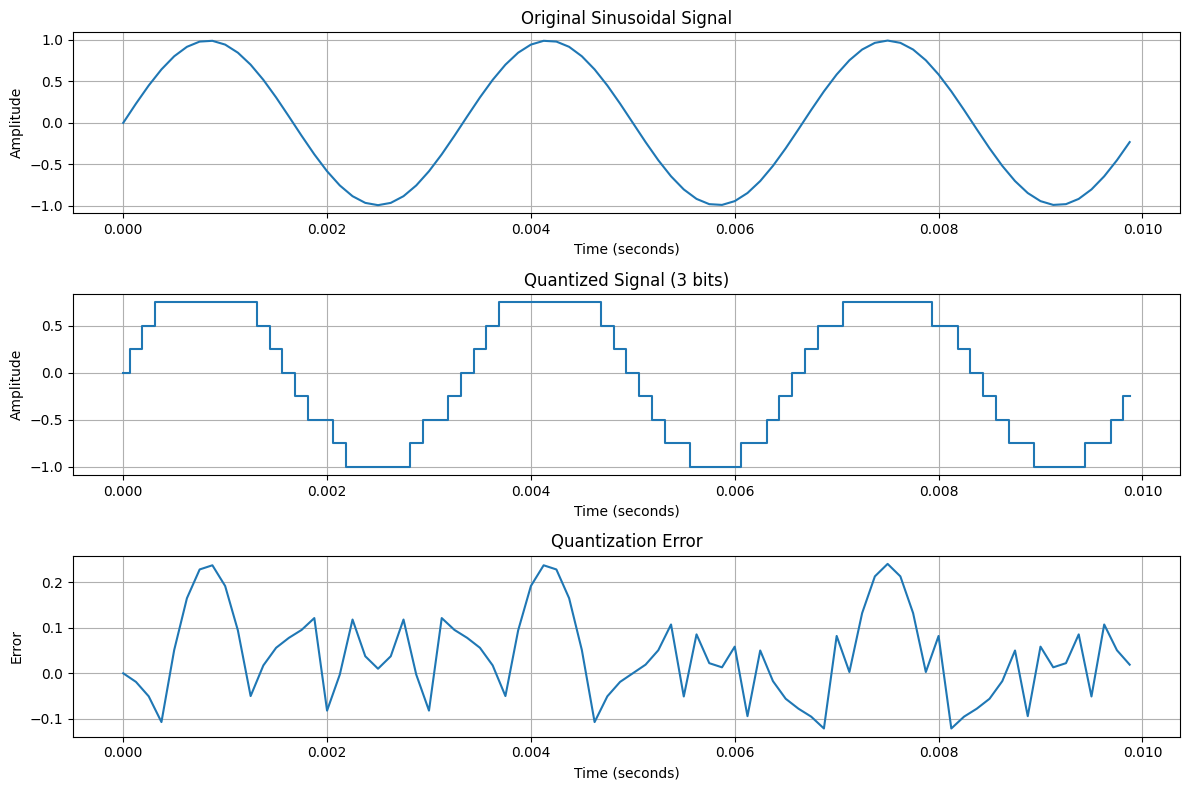

Number of bits: 3
Number of quantization levels: 8
Quantization step size: 0.25


In [7]:
# Task 2.3: Uniform Quantizer

# Define the uniform quantizer function
def quantize(x, bits, full_scale=1.0):
    delta = 2 * full_scale / (2 ** bits)
    q = np.round(x / delta) * delta
    return np.clip(q, -full_scale, full_scale - delta)

# Sampling frequency
fs = 8000

# Generate time vector
t = np.arange(0, 0.01, 1/fs)

# Generate a 300 Hz sinusoidal signal
x = 0.99 * np.sin(2 * np.pi * 300 * t)

# Quantize the signal using 3 bits
bits = 3
xq = quantize(x, bits)

# Calculate quantization error
error = x - xq

# Plot the signals
plt.figure(figsize=(12, 8))

plt.subplot(3, 1, 1)
plt.plot(t, x)
plt.title("Original Sinusoidal Signal")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.grid(True)

plt.subplot(3, 1, 2)
plt.step(t, xq, where="mid")
plt.title("Quantized Signal (3 bits)")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.grid(True)

plt.subplot(3, 1, 3)
plt.plot(t, error)
plt.title("Quantization Error")
plt.xlabel("Time (seconds)")
plt.ylabel("Error")
plt.grid(True)

plt.tight_layout()
plt.show()

# Display quantization information
delta = 2 / (2 ** bits)

print("Number of bits:", bits)
print("Number of quantization levels:", 2 ** bits)
print("Quantization step size:", delta)

### Observation

The original sinusoidal signal has a smooth and continuous range of amplitude values. After quantization using 3 bits, the signal is represented by 8 discrete amplitude levels, producing a staircase-like waveform.

The quantization error represents the difference between the original signal and the quantized signal. It varies with the signal amplitude because the quantized values are approximations of the original values.

The calculated quantization step size is 0.25.

### Conclusion

The experiment demonstrates that uniform quantization converts signal amplitudes into a finite number of discrete levels. The number of available levels depends on the number of bits used. Quantization introduces an error because the original signal amplitudes are rounded to the nearest available quantization levels.

## Task 2.4: Verify the 6 dB-per-bit Rule

### Objective
To investigate the relationship between the number of quantization bits and the Signal-to-Quantization-Noise Ratio (SQNR).

### Theory

The Signal-to-Quantization-Noise Ratio (SQNR) measures the ratio of the signal power to the quantization noise power.

It is expressed in decibels (dB) as:

$$SQNR = 10\log_{10}\left(\frac{\sum x[n]^2}{\sum e[n]^2}\right)$$

Where:

- $x[n]$ = Original signal.
- $e[n]$ = Quantization error.
- $SQNR$ = Signal-to-Quantization-Noise Ratio.

For an ideal uniform quantizer with a full-scale sinusoidal input, the theoretical SQNR is approximately:

$$SQNR = 6.02B + 1.76\text{ dB}$$

Where $B$ represents the number of quantization bits.

This relationship indicates that adding one bit to the quantizer improves the SQNR by approximately 6 dB.

### Procedure

A sinusoidal signal is quantized using different bit resolutions, ranging from 2 to 16 bits. The measured SQNR is calculated for each bit resolution and compared with the theoretical SQNR.

A graph is then plotted to show the relationship between the number of bits and SQNR.

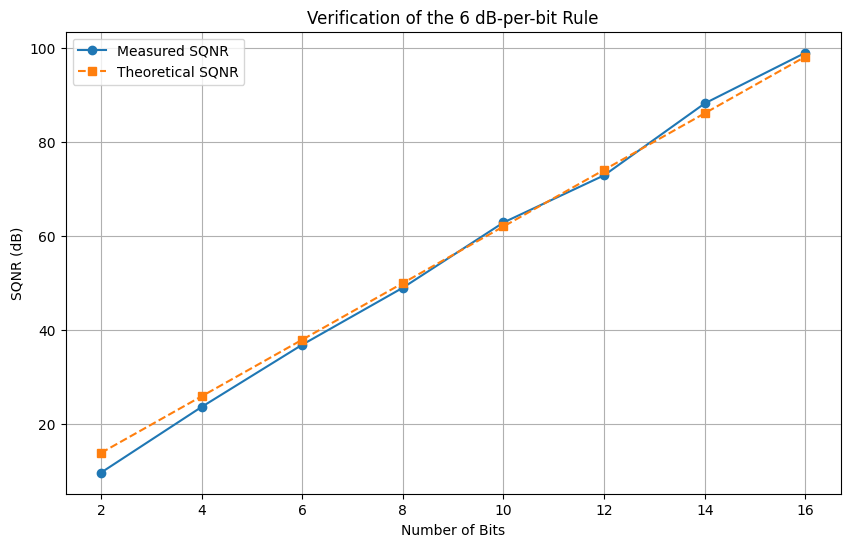

Bits | Measured SQNR (dB) | Theoretical SQNR (dB)
   2 |                9.60 |                 13.80
   4 |               23.58 |                 25.84
   6 |               36.81 |                 37.88
   8 |               48.93 |                 49.92
  10 |               62.81 |                 61.96
  12 |               72.84 |                 74.00
  14 |               88.13 |                 86.04
  16 |               98.91 |                 98.08


In [8]:
# Task 2.4: Verify the 6 dB-per-bit Rule

# Number of bits to investigate
bits_range = np.arange(2, 17, 2)

# Lists to store SQNR values
measured_sqnr = []
theoretical_sqnr = []

# Calculate SQNR for each bit resolution
for B in bits_range:

    # Quantize the original signal
    xq = quantize(x, B)

    # Calculate quantization error
    error = x - xq

    # Calculate measured SQNR
    sqnr = 10 * np.log10(
        np.sum(x ** 2) / np.sum(error ** 2)
    )

    measured_sqnr.append(sqnr)

    # Calculate theoretical SQNR
    theoretical = 6.02 * B + 1.76
    theoretical_sqnr.append(theoretical)

# Plot measured and theoretical SQNR
plt.figure(figsize=(10, 6))

plt.plot(
    bits_range,
    measured_sqnr,
    'o-',
    label="Measured SQNR"
)

plt.plot(
    bits_range,
    theoretical_sqnr,
    's--',
    label="Theoretical SQNR"
)

plt.title("Verification of the 6 dB-per-bit Rule")
plt.xlabel("Number of Bits")
plt.ylabel("SQNR (dB)")
plt.xticks(bits_range)
plt.grid(True)
plt.legend()
plt.show()

# Display results
print("Bits | Measured SQNR (dB) | Theoretical SQNR (dB)")

for B, measured, theoretical in zip(
    bits_range, measured_sqnr, theoretical_sqnr
):
    print(f"{B:4d} | {measured:19.2f} | {theoretical:21.2f}")

### Observation

The graph shows that the measured and theoretical SQNR increase as the number of quantization bits increases.

The theoretical SQNR increases by approximately 6.02 dB for every additional bit. Therefore, increasing the bit resolution improves the accuracy of quantization by reducing the quantization noise.

The measured SQNR generally follows the theoretical trend, although small differences may occur due to the signal amplitude and quantization effects.

### Conclusion

The experiment verifies the 6 dB-per-bit rule, which states that increasing the quantization resolution by one bit improves the theoretical SQNR by approximately 6 dB.

Therefore, using more quantization bits improves digital signal quality by providing more amplitude levels and reducing quantization error.

## Task 2.5: Quantize Your Voice

### Objective
To investigate the effects of different quantization resolutions on a recorded speech signal by quantizing the voice recording at 4 bits, 8 bits and 12 bits.

### Theory

A recorded speech signal contains different amplitude levels and frequency components. Quantization converts these amplitude values into a finite number of discrete levels.

The number of available quantization levels is determined by:

$$L = 2^B$$

Where:

- $L$ = Number of quantization levels.
- $B$ = Number of quantization bits.

In this experiment, the voice recording is quantized using three different bit resolutions:

- 4 bits provide 16 quantization levels.
- 8 bits provide 256 quantization levels.
- 12 bits provide 4096 quantization levels.

The Signal-to-Quantization-Noise Ratio (SQNR) is calculated to evaluate the quality of each quantized recording.

### Procedure

The voice recording from Week 1 is used as the input signal. It is quantized separately using 4-bit, 8-bit and 12-bit resolutions.

The resulting audio signals are played back and compared to observe how quantization resolution affects speech quality. The SQNR is also calculated for each resolution.

In [11]:
# Task 2.5: Quantize Your Voice

# Load the original voice recording
fname = "voice.wav"
fs, x = wavfile.read(fname)

# Convert stereo audio to mono if necessary
if x.ndim > 1:
    x = x.mean(axis=1)

# Convert audio samples to floating-point values
voice = x.astype(float)

# Normalize the voice signal
voice = voice / np.max(np.abs(voice))

# Bit resolutions to investigate
bit_values = [4, 8, 12]

# Store SQNR results
voice_sqnr = []

for B in bit_values:

    # Quantize the voice signal
    voice_quantized = quantize(voice, B)

    # Calculate quantization error
    error = voice - voice_quantized

    # Calculate SQNR
    sqnr = 10 * np.log10(
        np.sum(voice ** 2) / np.sum(error ** 2)
    )

    voice_sqnr.append(sqnr)

    print(f"\nQuantization resolution: {B} bits")
    print(f"Number of levels: {2 ** B}")
    print(f"Measured SQNR: {sqnr:.2f} dB")

    # Play quantized audio
    display(Audio(voice_quantized, rate=fs))


Quantization resolution: 4 bits
Number of levels: 16
Measured SQNR: 11.72 dB



Quantization resolution: 8 bits
Number of levels: 256
Measured SQNR: 32.87 dB



Quantization resolution: 12 bits
Number of levels: 4096
Measured SQNR: 56.93 dB


### Observation

The voice recording was quantized using 4-bit, 8-bit and 12-bit resolutions.

The measured SQNR values were:

- 4 bits: 11.72 dB
- 8 bits: 32.87 dB
- 12 bits: 56.93 dB

The results indicate that SQNR increases as the number of quantization bits increases. The 4-bit quantized signal has the lowest SQNR, while the 12-bit quantized signal has the highest SQNR.

This demonstrates that higher quantization resolution reduces quantization noise and improves the accuracy of the digital representation of the recorded voice.

### Conclusion

The experiment demonstrates that increasing the number of quantization bits improves the quality of a digital audio signal by providing more amplitude levels and reducing quantization error.

The measured SQNR values are different from those expected for a full-scale sinusoidal signal because speech has varying amplitude levels and does not consistently use the full quantization range.

### Analysis Question 1

**Why does a 7 Hz tone appear at 3 Hz when sampled at 10 Hz?**

A 7 Hz sinusoidal signal appears at 3 Hz when sampled at 10 Hz because of a phenomenon known as aliasing.

According to the Nyquist sampling theorem, the sampling frequency must be at least twice the highest frequency component of a signal to avoid aliasing.

The Nyquist frequency is:

$$f_N=\frac{f_s}{2}=\frac{10}{2}=5\text{ Hz}$$

Since the original signal frequency of 7 Hz exceeds the Nyquist frequency of 5 Hz, aliasing occurs.

The apparent alias frequency is calculated as:

$$f_{\text{alias}}=|f_0-f_s|$$

$$f_{\text{alias}}=|7-10|=3\text{ Hz}$$

Therefore, the original 7 Hz signal appears as a 3 Hz signal after sampling at 10 Hz.

### Analysis Question 2

**Why can't aliasing in naïve downsampling be removed afterwards?**

Aliasing in naïve downsampling cannot be reliably removed afterwards because different frequency components overlap when the sampling frequency is reduced without applying an anti-aliasing filter.

This causes high-frequency components to appear as incorrect lower-frequency components. Once these frequency components overlap, it becomes difficult or impossible to distinguish the original frequencies.

Applying a filter after downsampling cannot reliably recover the lost frequency information because the original and aliased components are no longer distinguishable.

Therefore, an anti-aliasing low-pass filter must be applied before downsampling to remove frequency components that exceed the new Nyquist frequency.

### Analysis Question 3

**By how much does SQNR change when one bit is added? Does your measurement agree?**

The theoretical SQNR increases by approximately 6.02 dB for every additional quantization bit, according to:

$$SQNR=6.02B+1.76$$

From my measured voice quantization results:

- From 4 to 8 bits, SQNR increased from 11.72 dB to 32.87 dB, giving an average improvement of 5.29 dB per bit.
- From 8 to 12 bits, SQNR increased from 32.87 dB to 56.93 dB, giving an average improvement of approximately 6.02 dB per bit.

The results show that the measured SQNR generally agrees with the theoretical 6 dB-per-bit rule, particularly between 8 and 12 bits. Small differences may occur because speech signals do not have the constant amplitude characteristics of an ideal full-scale sinusoidal signal.

### Analysis Question 4

**A temperature sensor changes at a maximum rate of 0.1°C/s and has a required resolution of 0.01°C over a range of 0–100°C. Suggest a suitable sampling rate and number of bits, with justification.**

**1. Sampling Rate**

The maximum temperature change is 0.1°C per second. A suitable sampling rate is 10 Hz, meaning that the temperature is sampled 10 times per second, or once every 0.1 seconds.

This allows the system to monitor temperature changes frequently enough to track the specified rate.

**2. Number of Quantization Bits**

The temperature range is 0–100°C, and the required resolution is 0.01°C.

The required number of quantization levels is:

$$L=\frac{100}{0.01}=10,000$$

The number of bits required is:

$$B=\lceil\log_2(10,000)\rceil$$

$$B=\lceil13.29\rceil=14\text{ bits}$$

A 14-bit quantizer provides:

$$2^{14}=16,384\text{ levels}$$

This provides sufficient quantization levels to achieve the required 0.01°C resolution.

**Conclusion**

A suitable sampling rate is 10 Hz, with a minimum quantization resolution of 14 bits. This combination provides frequent temperature measurements and sufficient amplitude resolution for the specified temperature range.

## AI Use Statement

I used ChatGPT (OpenAI) as an AI assistance tool during the completion of this Digital Signal Processing laboratory exercise. It was used to support my understanding of DSP concepts, explain laboratory procedures, assist with Python code development and debugging, and help interpret the generated signal plots, audio outputs and experimental results.

AI assistance was also used to clarify concepts related to sampling, aliasing, quantization and Signal-to-Quantization-Noise Ratio (SQNR).

I personally executed and verified the code in Google Colab, performed the practical activities, listened to the quantized audio recordings, and reviewed the experimental results. The observations, analysis and conclusions were reviewed and adapted to reflect my own understanding of the laboratory activities.

AI was used as a learning support tool and not as a replacement for my own practical work, critical thinking and understanding.